In [ ]:
import torch

print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA: True
GPU: Tesla T4


In [ ]:
from pathlib import Path
import subprocess

repo = Path("/content/GATv2")

if not (repo / ".git").is_dir():
    if repo.exists():
        raise RuntimeError(
            "Thư mục /content/GATv2 đã tồn tại nhưng không phải Git repo. "
            "Hãy kiểm tra trước khi chạy tiếp."
        )
    subprocess.run([
        "git", "clone", "-b", "fix/gatv2-skip-pipeline",
        "--single-branch",
        "https://github.com/pdmh18/GATv2.git",
        str(repo)
    ], check=True)

commit = subprocess.check_output(
    ["git", "-C", str(repo), "rev-parse", "--short", "HEAD"],
    text=True
).strip()

assert commit == "d89a00e", f"Sai commit: {commit}"
print("SOURCE: OK")
print("COMMIT:", commit)

SOURCE: OK
COMMIT: d89a00e


In [ ]:
from google.colab import userdata

token = userdata.get("KAGGLE_API_TOKEN")
print("Kaggle Secret:", "OK" if token else "Missing")

Kaggle Secret: OK


In [ ]:

import json
from pathlib import Path

repo = Path("/content/GATv2")

cfg = json.loads(
    (repo / "configs/review-v2.json").read_text()
)

base = "outputs/contextual-v5-device/seed-20261002"

# Dùng cùng raw dataset, tạo artifact mới
cfg["dataset"]["validation_report"] = f"{base}/validation/skip-v2/validation.json"
cfg["dataset"]["output"] = f"{base}/splits/skip-v2"
cfg["dataset"]["features_output"] = f"{base}/features-v3/skip-v2"

# Train GATv2 Skip v2 bằng GPU
cfg["training"]["model_kind"] = "gatv2_skip"
cfg["training"]["device"] = "cuda"
cfg["training"]["output"] = f"{base}/training/gatv2-skip-v2"
cfg["training"]["epochs"] = 5

# Đánh giá riêng
cfg["evaluation"]["output"] = f"{base}/evaluation/gatv2-skip-v2"

target = repo / "configs/skip-v2-colab.json"
target.write_text(json.dumps(cfg, indent=2), encoding="utf-8")

print("Config:", target)
print("Model:", cfg["training"]["model_kind"])
print("Device:", cfg["training"]["device"])
print("Features:", cfg["dataset"]["features_output"])
print("Training:", cfg["training"]["output"])


Config: /content/GATv2/configs/skip-v2-colab.json
Model: gatv2_skip
Device: cuda
Features: outputs/contextual-v5-device/seed-20261002/features-v3/skip-v2
Training: outputs/contextual-v5-device/seed-20261002/training/gatv2-skip-v2


In [ ]:

import kagglehub
from pathlib import Path

raw_path = Path(kagglehub.dataset_download(
    "phmnhminhhiu/anomalybank-gatv2-seed-20261002/versions/1",
    path="contextual-v5-device/seed-20261002/raw"
))

print("RAW:", raw_path)
print("Thư mục tồn tại:", raw_path.is_dir())

if raw_path.is_dir():
    print("Các file dữ liệu:")
    for f in sorted(raw_path.iterdir()):
        print("-", f.name)


RAW: /root/.cache/kagglehub/datasets/phmnhminhhiu/anomalybank-gatv2-seed-20261002/versions/1/contextual-v5-device/seed-20261002/raw
Thư mục tồn tại: True
Các file dữ liệu:
- accounts.jsonl
- behavior_profiles.jsonl
- counterparties.jsonl
- customers.jsonl
- events.jsonl
- labels.jsonl
- loan_applications.jsonl
- loan_packages.jsonl
- loans.jsonl
- manifest.json
- transactions.jsonl
- transfer_events.jsonl


In [ ]:

from pathlib import Path

source = Path(raw_path).resolve()

destination = Path(
    "/content/GATv2/outputs/contextual-v5-device/"
    "seed-20261002/raw"
)

destination.parent.mkdir(parents=True, exist_ok=True)

if not destination.exists() and not destination.is_symlink():
    destination.symlink_to(source, target_is_directory=True)

assert destination.resolve() == source
assert (destination / "manifest.json").is_file()
assert (destination / "events.jsonl").is_file()
assert (destination / "labels.jsonl").is_file()

print("RAW DATA: OK")
print("Số file:", len(list(destination.iterdir())))
print("Đường dẫn:", destination)


RAW DATA: OK
Số file: 12
Đường dẫn: /content/GATv2/outputs/contextual-v5-device/seed-20261002/raw


In [ ]:
%pip install -q torch-geometric

import torch
import torch_geometric
from torch_geometric.nn import GATv2Conv

print("PyTorch:", torch.__version__)
print("PyTorch Geometric:", torch_geometric.__version__)
print("CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")
print("GATv2Conv: OK")

assert torch.cuda.is_available(), "Chưa bật GPU trong Colab!"

PyTorch: 2.11.0+cu130
PyTorch Geometric: 2.8.1
CUDA: True
GPU: Tesla T4
GATv2Conv: OK


In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

# Đặt tên riêng cho mỗi lần thực nghiệm
RUN_ID = "skip-v2-run-01"

backup_root = Path(
    "/content/drive/MyDrive/AnomalyBank/GATv2/skip-v2-runs"
) / RUN_ID

assert not (backup_root / "training" / "best.pt").exists(), (
    "Lần train này đã có checkpoint. Hãy đổi RUN_ID!"
)

backup_root.mkdir(parents=True, exist_ok=True)

print("Google Drive:", "OK" if backup_root.is_dir() else "ERROR")
print("Thư mục:", backup_root)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive: OK
Thư mục: /content/drive/MyDrive/AnomalyBank/GATv2/skip-v2-runs/skip-v2-run-01


In [ ]:

import json
from pathlib import Path

repo = Path("/content/GATv2")
config_path = repo / "configs/skip-v2-colab.json"

cfg = json.loads(config_path.read_text(encoding="utf-8"))

# Lưu checkpoint và evaluation lên Google Drive
cfg["training"]["output"] = str(backup_root / "training")
cfg["evaluation"]["output"] = str(backup_root / "evaluation")

# Graph cache riêng cho từng lần train, lưu tại Colab
cfg["training"]["context_cache"] = str(
    repo / "outputs/contextual-v5-device"
    / "seed-20261002/contexts" / RUN_ID
)

assert cfg["training"]["model_kind"] == "gatv2_skip"
assert cfg["training"]["device"] == "cuda"

# Tránh ghi đè kết quả train cũ
for key in ("training", "evaluation"):
    assert not Path(cfg[key]["output"]).exists(), (
        f"Output already exists: {cfg[key]['output']}"
    )

# Lưu config trên Colab
config_path.write_text(
    json.dumps(cfg, indent=2) + "\n",
    encoding="utf-8"
)

# Sao lưu config lên Google Drive
(backup_root / "skip-v2-colab.json").write_text(
    json.dumps(cfg, indent=2) + "\n",
    encoding="utf-8"
)

print("CONFIG: OK")
print("Model:", cfg["training"]["model_kind"])
print("Device:", cfg["training"]["device"])
print("Training:", cfg["training"]["output"])
print("Evaluation:", cfg["evaluation"]["output"])
print("Cache:", cfg["training"]["context_cache"])


CONFIG: OK
Model: gatv2_skip
Device: cuda
Training: /content/drive/MyDrive/AnomalyBank/GATv2/skip-v2-runs/skip-v2-run-01/training
Evaluation: /content/drive/MyDrive/AnomalyBank/GATv2/skip-v2-runs/skip-v2-run-01/evaluation
Cache: /content/GATv2/outputs/contextual-v5-device/seed-20261002/contexts/skip-v2-run-01


In [ ]:
%cd /content/GATv2

!CUBLAS_WORKSPACE_CONFIG=:4096:8 python -u scripts/run_pipeline.py --stage all --config configs/skip-v2-colab.json

/content/GATv2
Validated dataset, split and feature artifacts; starting training
epoch=1 train batches=200 samples=16759 loss=1.5881
epoch=1 train batches=400 samples=32509 loss=1.0786
epoch=1 train batches=600 samples=47965 loss=0.8115
epoch=1 train batches=800 samples=63189 loss=0.6587
epoch=1 train batches=1000 samples=80787 loss=0.5429
epoch=1 train batches=1200 samples=99694 loss=0.4587
epoch=1 train batches=1400 samples=116258 loss=0.4045
epoch=1 train batches=1600 samples=131931 loss=0.3631
epoch=1 train batches=1800 samples=147741 loss=0.3313
epoch=1 train batches=2000 samples=163250 loss=0.3041
epoch=1 train batches=2200 samples=179697 loss=0.2810
epoch=1 train batches=2400 samples=195001 loss=0.2625
epoch=1 train batches=2600 samples=210610 loss=0.2469
epoch=1 train batches=2800 samples=225819 loss=0.2339
epoch=1 train batches=3000 samples=241398 loss=0.2223
epoch=1 validation batches=200 samples=16367 loss=0.0511
epoch=1 validation batches=400 samples=31658 loss=0.0423
epoch

In [ ]:

import json
from pathlib import Path

repo = Path("/content/GATv2")

# Dùng đúng thư mục của lần train 5 epochs
root = backup_root
training = root / "training"
evaluation = root / "evaluation"

cfg = json.loads(
    (repo / "configs/skip-v2-colab.json").read_text(encoding="utf-8")
)

# Dùng checkpoint vừa huấn luyện
cfg["training"]["output"] = str(training)

# Chỉ đánh giá Skip v2, không train model khác
cfg["evaluation"]["train_variants"] = []
cfg["evaluation"]["output"] = str(evaluation)

# Kiểm tra checkpoint 5 epochs
assert (training / "best.pt").is_file()
assert (training / "config.json").is_file()

saved_config = json.loads(
    (training / "config.json").read_text(encoding="utf-8")
)

assert cfg["training"]["model_kind"] == "gatv2_skip"
assert saved_config["model_kind"] == "gatv2_skip"
assert saved_config["epochs"] == 5
assert cfg["training"]["epochs"] == 5

# Kiểm tra kiến trúc và cấu hình huấn luyện khớp nhau
for key in (
    "seed", "batch_size", "snapshot_seconds",
    "learning_rate", "weight_decay", "model"
):
    assert cfg["training"][key] == saved_config[key], key

# Không ghi đè kết quả Evaluation cũ
assert not evaluation.exists(), (
    "Evaluation đã tồn tại, cần kiểm tra trước khi chạy."
)

# Tạo config riêng cho Evaluation
target = repo / "configs/skip-v2-eval-colab.json"

target.write_text(
    json.dumps(cfg, indent=2) + "\n",
    encoding="utf-8"
)

print("EVALUATION CONFIG: OK")
print("RUN:", RUN_ID)
print("MODEL:", cfg["training"]["model_kind"])
print("EPOCHS:", saved_config["epochs"])
print("CHECKPOINT:", training / "best.pt")
print("OUTPUT:", evaluation)
print("TRAIN VARIANTS:", cfg["evaluation"]["train_variants"])


EVALUATION CONFIG: OK
RUN: skip-v2-run-01
MODEL: gatv2_skip
EPOCHS: 5
CHECKPOINT: /content/drive/MyDrive/AnomalyBank/GATv2/skip-v2-runs/skip-v2-run-01/training/best.pt
OUTPUT: /content/drive/MyDrive/AnomalyBank/GATv2/skip-v2-runs/skip-v2-run-01/evaluation
TRAIN VARIANTS: []


In [ ]:
%cd /content/GATv2

!python -u scripts/run_pipeline.py --stage evaluate --config configs/skip-v2-eval-colab.json

/content/GATv2
Frozen selection: gatv2_skip. Beginning final test scoring.
gatv2_skip test F1=0.9581


In [ ]:

import json
from pathlib import Path

# Kết quả của lần train hiện tại
root = backup_root
evaluation = root / "evaluation"
figures = evaluation / "figures"

report_path = evaluation / "report.json"
assert report_path.is_file(), "Chưa có report.json. Hãy chạy Khối 12 trước."

report = json.loads(report_path.read_text(encoding="utf-8"))
metrics = report["comparisons"]["gatv2_skip"]["test"]

print("RUN:", RUN_ID)
print("MODEL:", report["selected_model"])
print("\n===== TEST RESULTS =====")

for name in [
    "precision", "recall", "f1",
    "average_precision", "roc_auc"
]:
    print(f"{name}: {metrics[name]:.4f}")

print("\n===== BIỂU ĐỒ =====")

for name in [
    "roc_pr_curves",
    "confusion_matrix",
    "gatv2_metrics"
]:
    path = figures / f"{name}.png"
    print(name, "OK" if path.is_file() else "MISSING")

print(
    "PDF tổng hợp:",
    (figures / "evaluation_charts.pdf").is_file()
)

print(
    "Learning Curves:",
    (root / "training/learning_curves.png").is_file()
)


RUN: skip-v2-run-01
MODEL: gatv2_skip

===== TEST RESULTS =====
precision: 0.9600
recall: 0.9562
f1: 0.9581
average_precision: 0.9830
roc_auc: 0.9997

===== BIỂU ĐỒ =====
roc_pr_curves OK
confusion_matrix OK
gatv2_metrics OK
PDF tổng hợp: True
Learning Curves: True


RUN: skip-v2-run-01
THƯ MỤC: /content/drive/MyDrive/AnomalyBank/GATv2/skip-v2-runs/skip-v2-run-01
EPOCHS: 5
BEST EPOCH: 5

 1. Learning Curves


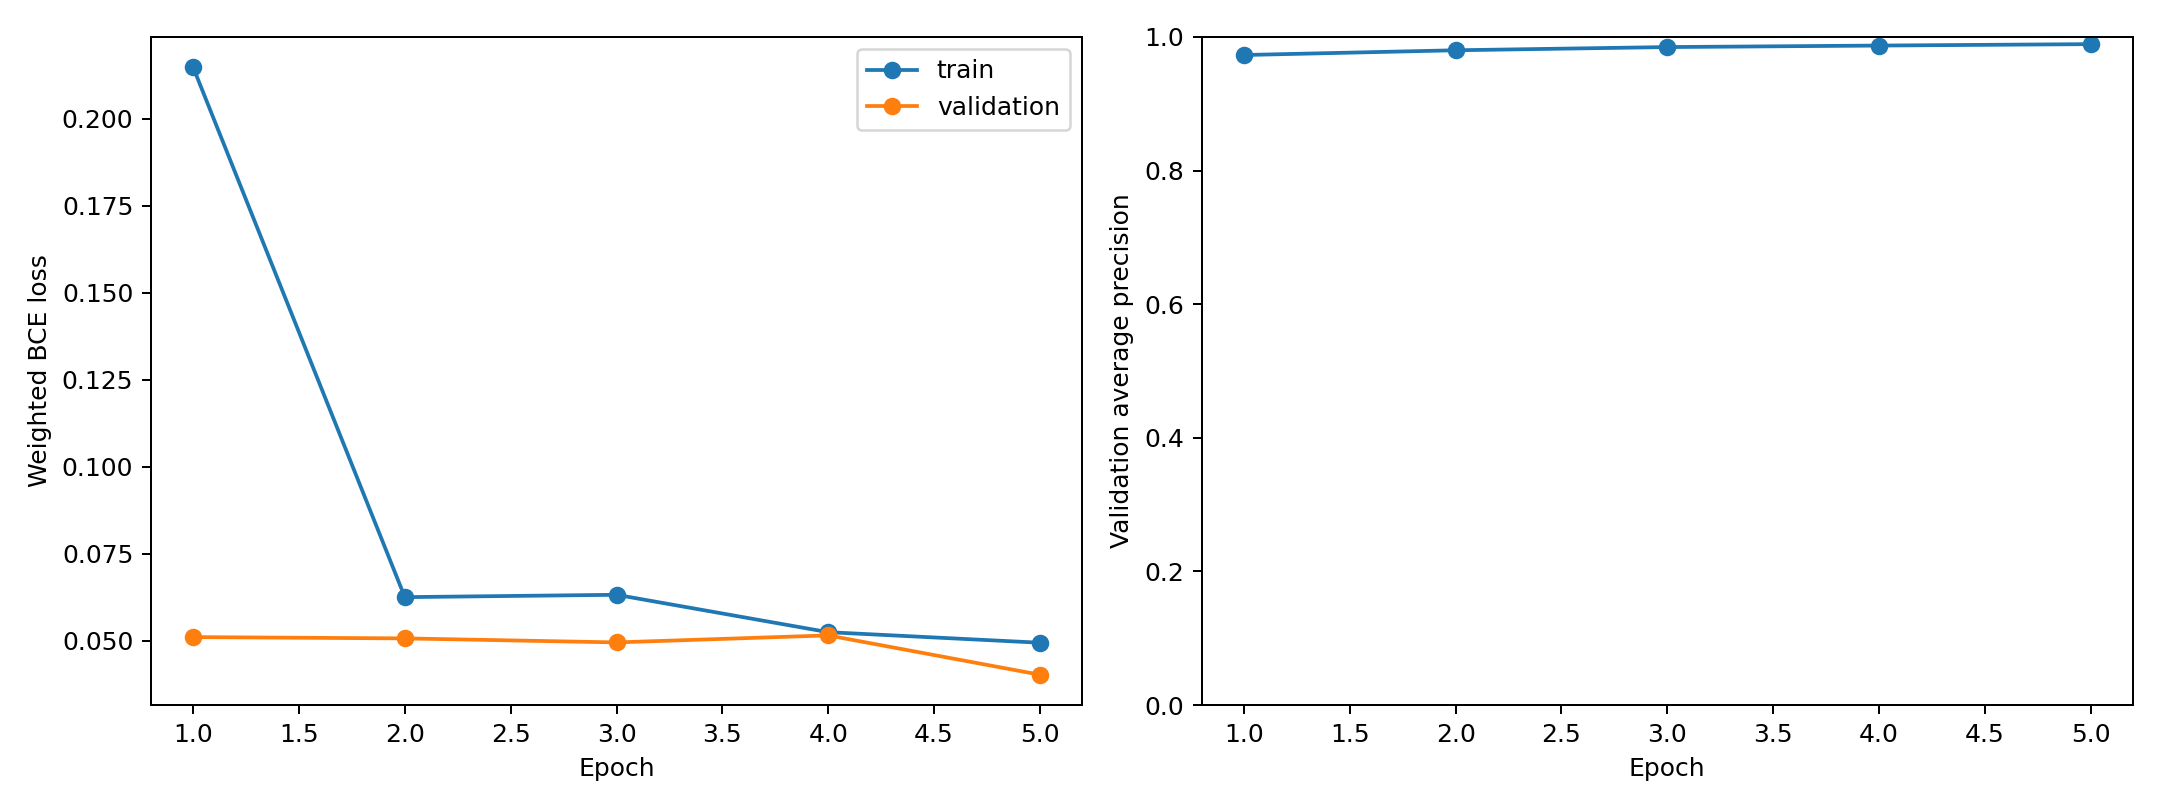


 2. Precision-Recall & ROC


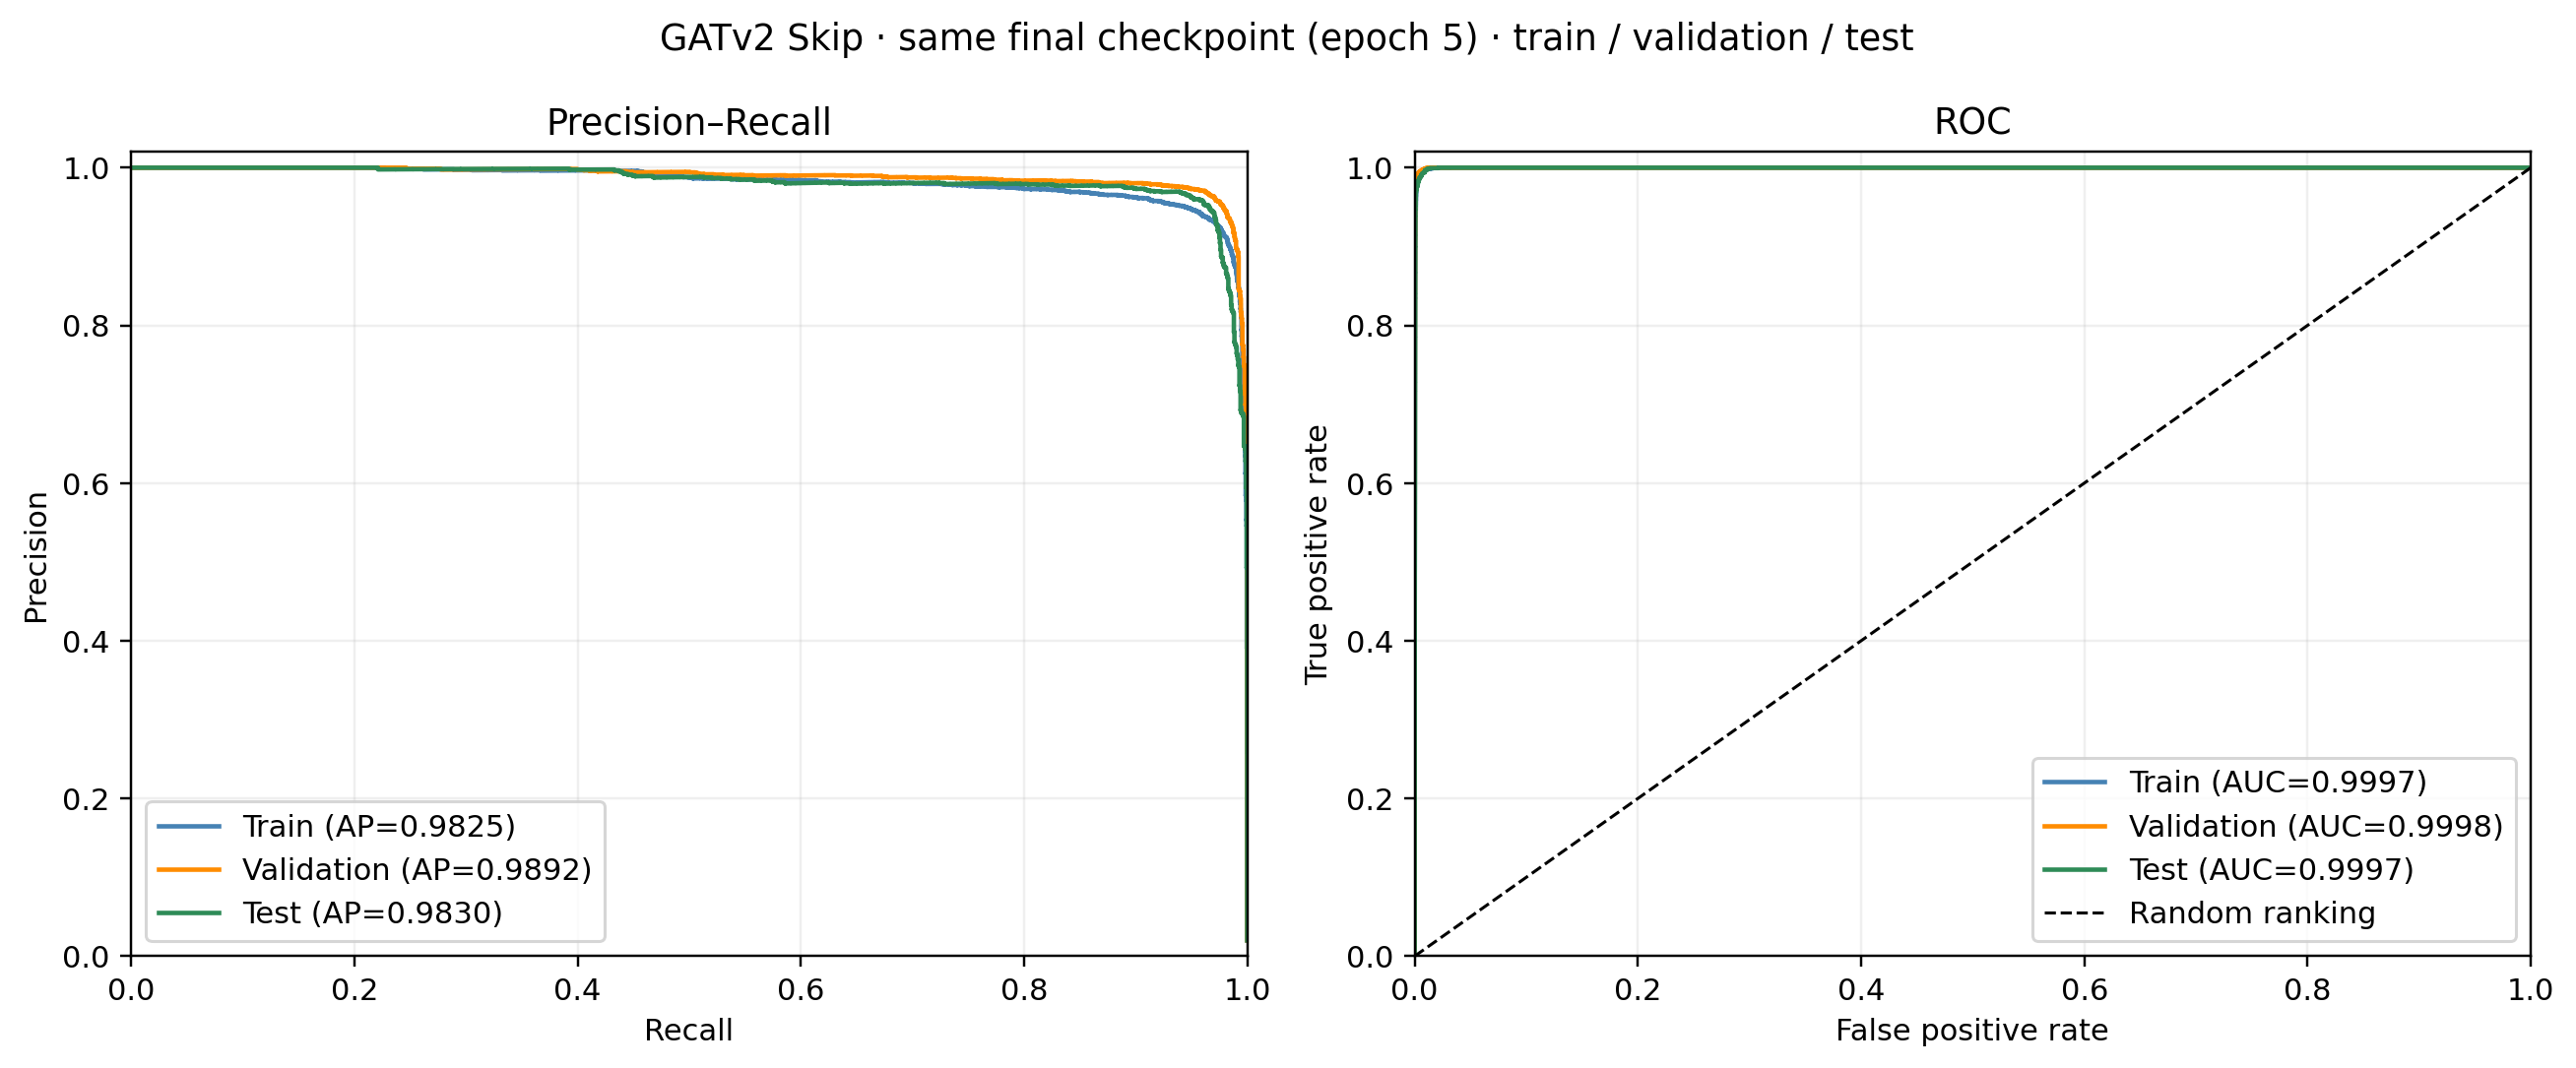


 3. Confusion Matrix


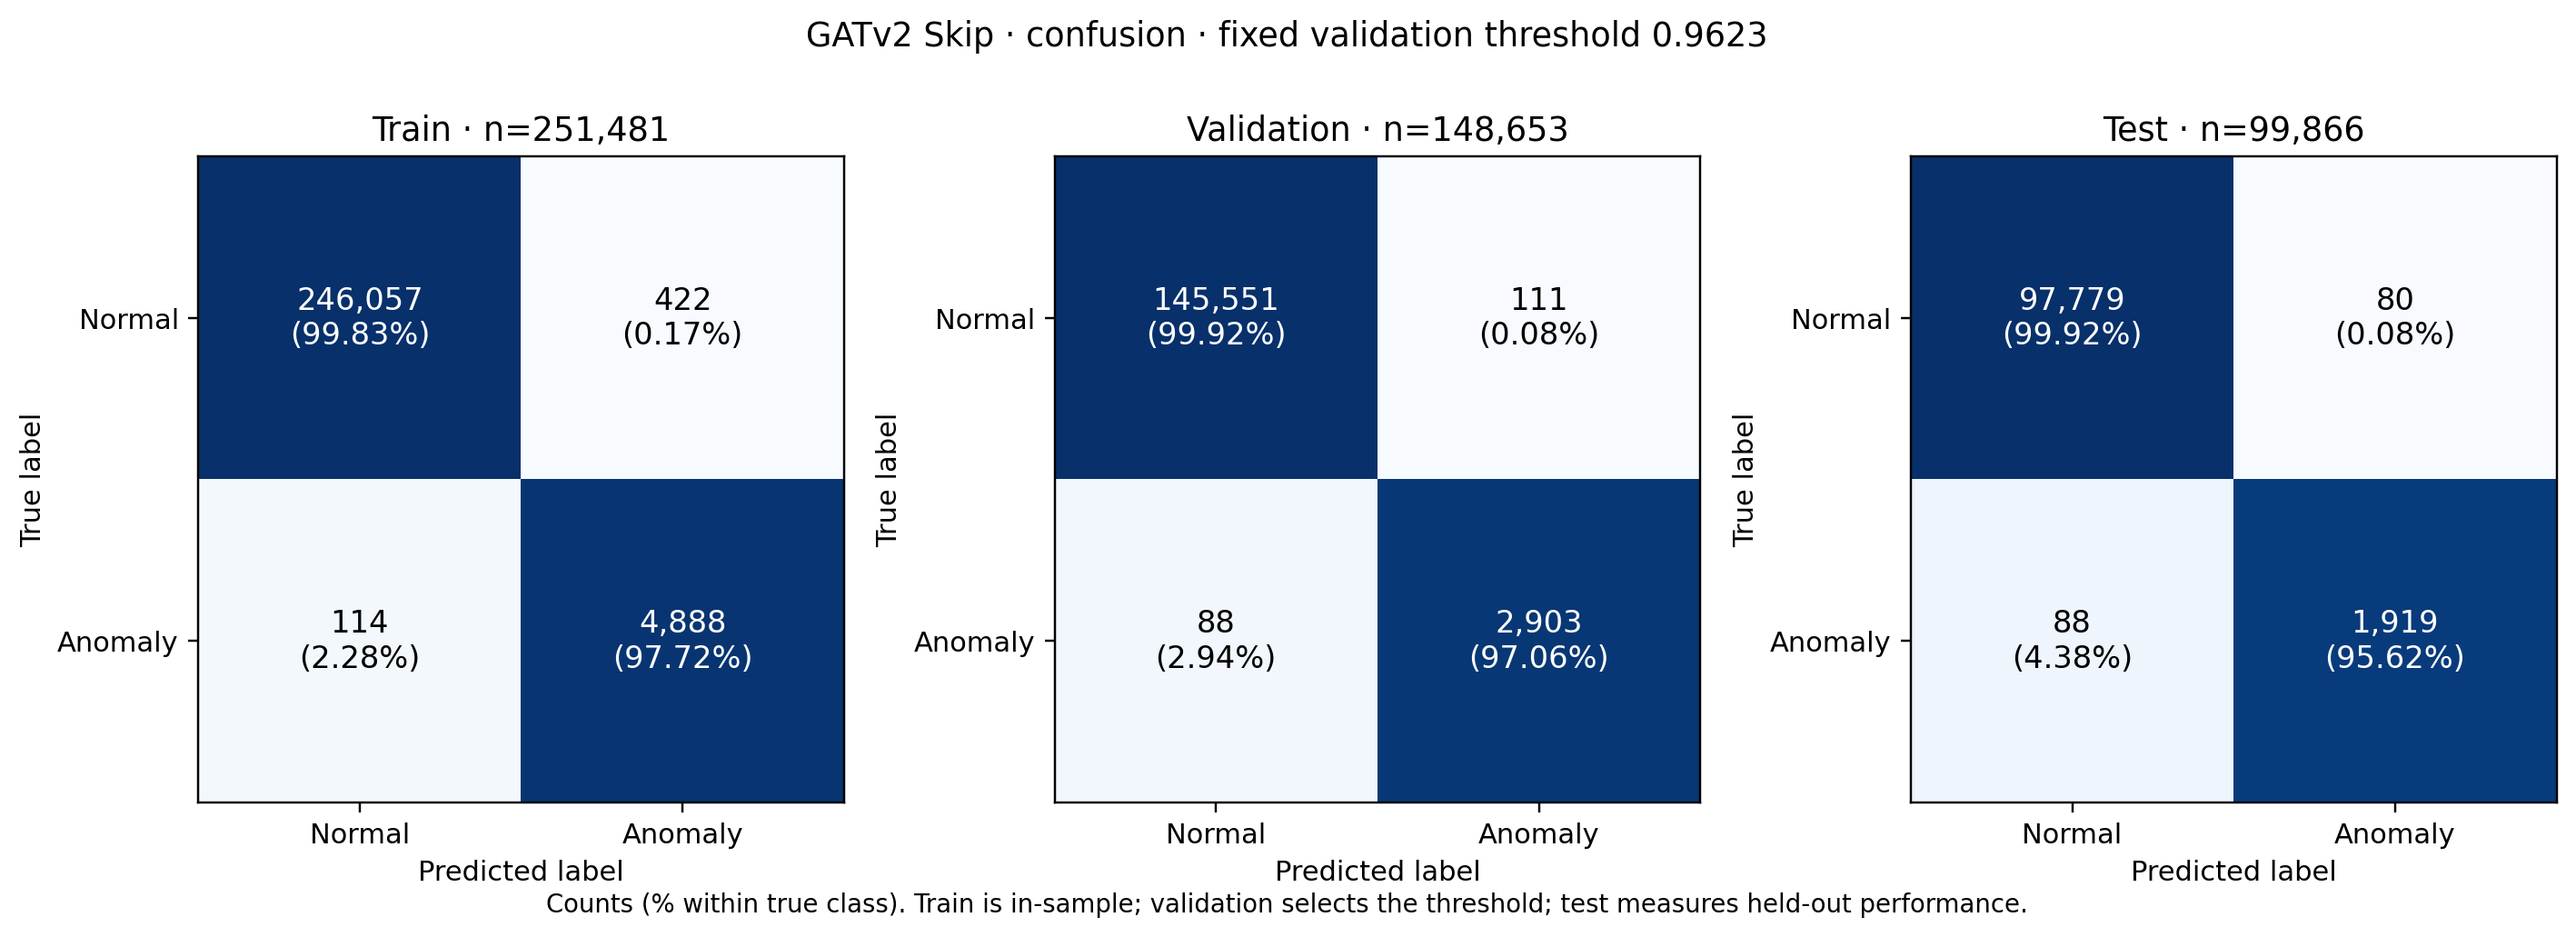


 4. Metrics


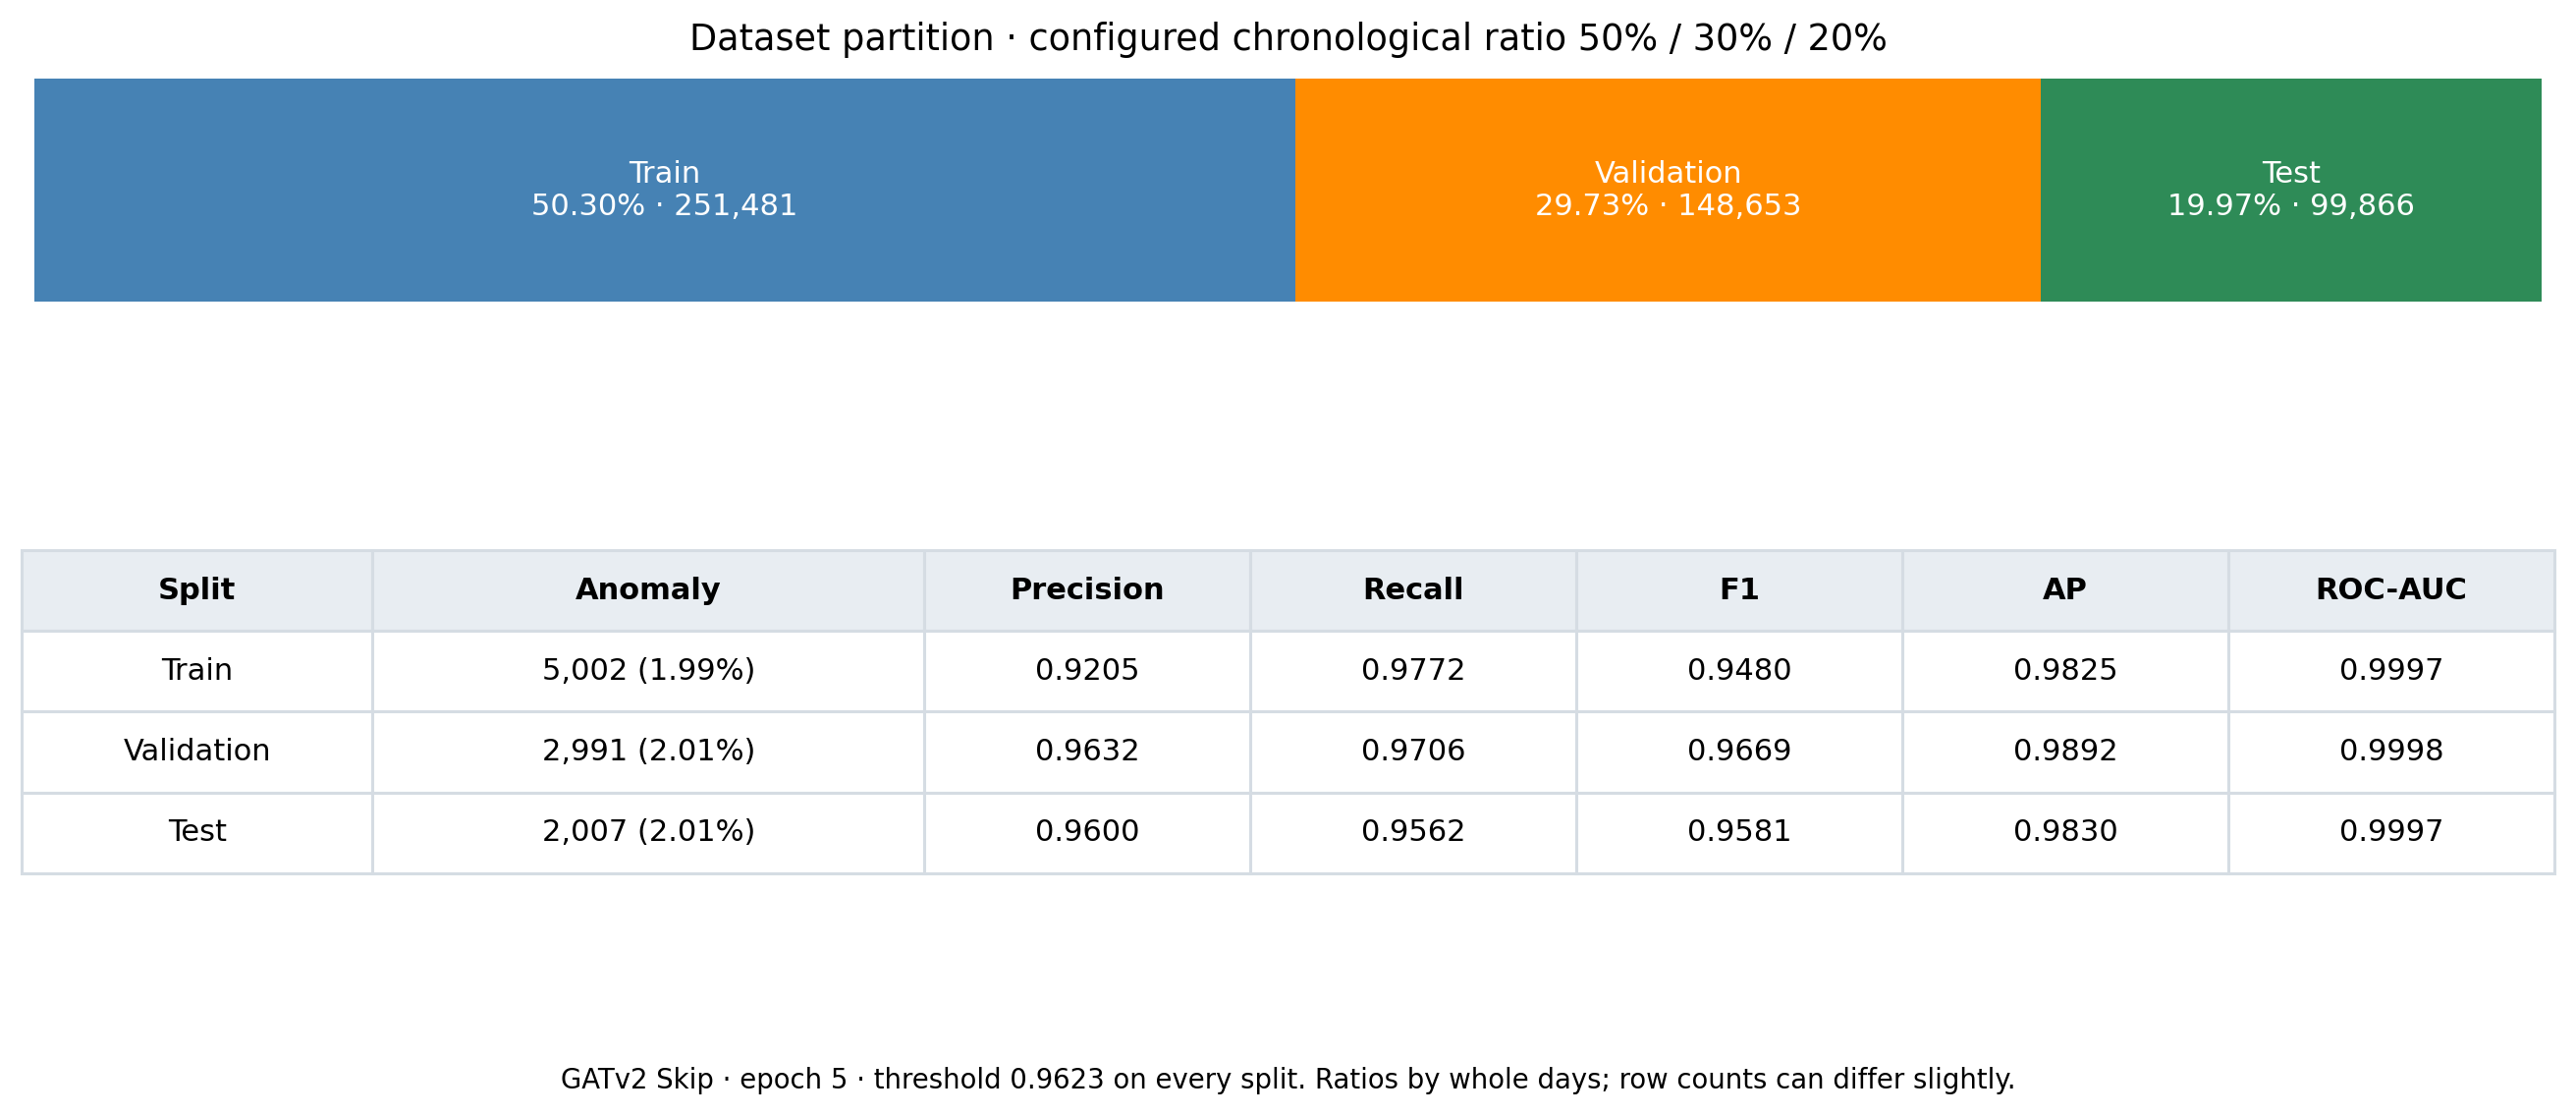

In [ ]:
import json
from IPython.display import display, Image

# Bắt buộc lấy biểu đồ của lần train hiện tại
chart_root = backup_root

summary = json.loads(
    (chart_root / "training/summary.json").read_text()
)

print("RUN:", RUN_ID)
print("THƯ MỤC:", chart_root)
print("EPOCHS:", summary["epochs_completed"])
print("BEST EPOCH:", summary["best_epoch"])

assert summary["epochs_completed"] == 5

charts = {
    "1. Learning Curves":
        chart_root / "training/learning_curves.png",
    "2. Precision-Recall & ROC":
        chart_root / "evaluation/figures/roc_pr_curves.png",
    "3. Confusion Matrix":
        chart_root / "evaluation/figures/confusion_matrix.png",
    "4. Metrics":
        chart_root / "evaluation/figures/gatv2_metrics.png",
}

for name, path in charts.items():
    assert path.is_file(), f"Thiếu biểu đồ: {path}"
    print("\n", name)
    display(Image(filename=str(path), width=950))

In [ ]:
import json
from pathlib import Path

print("RUN_ID:", RUN_ID)
print("BACKUP ROOT:", backup_root)
print("CHART ROOT:", root)

summary_path = backup_root / "training/summary.json"
report_path = backup_root / "evaluation/report.json"

if summary_path.is_file():
    summary = json.loads(summary_path.read_text())
    print("EPOCHS COMPLETED:", summary["epochs_completed"])
    print("BEST EPOCH:", summary["best_epoch"])
else:
    print("TRAINING SUMMARY: MISSING")

print("EVALUATION REPORT:", report_path.is_file())
print(
    "LEARNING CURVES:",
    backup_root / "training/learning_curves.png"
)

RUN_ID: skip-v2-run-01
BACKUP ROOT: /content/drive/MyDrive/AnomalyBank/GATv2/skip-v2-runs/skip-v2-run-01
CHART ROOT: /content/drive/MyDrive/AnomalyBank/GATv2/skip-v2
EPOCHS COMPLETED: 5
BEST EPOCH: 5
EVALUATION REPORT: True
LEARNING CURVES: /content/drive/MyDrive/AnomalyBank/GATv2/skip-v2-runs/skip-v2-run-01/training/learning_curves.png


In [ ]:
import json
from pathlib import Path

old = Path("/content/drive/MyDrive/AnomalyBank/GATv2/skip-v2")
new = backup_root

for name, folder in [
    ("3 epochs", old),
    ("5 epochs", new),
]:
    report = json.loads(
        (folder / "evaluation/report.json").read_text()
    )

    metrics = report["comparisons"]["gatv2_skip"]["test"]

    print(f"\n===== {name} =====")
    for key in [
        "precision", "recall", "f1",
        "average_precision", "roc_auc"
    ]:
        print(f"{key}: {metrics[key]:.6f}")


===== 3 epochs =====
precision: 0.945374
recall: 0.957150
f1: 0.951226
average_precision: 0.976873
roc_auc: 0.999543

===== 5 epochs =====
precision: 0.959980
recall: 0.956153
f1: 0.958063
average_precision: 0.983043
roc_auc: 0.999669


SINH 200K data

In [ ]:
from pathlib import Path

generator = Path("/content/anomaly-data-pipeline")

print("Generator:", "OK" if (generator / "src/anomaly_data_pipeline").is_dir() else "MISSING")
print("Base config:", (generator / "configs/base.yaml").is_file())
print("Pipeline config:", (generator / "configs/pipeline.toml").is_file())

Generator: MISSING
Base config: False
Pipeline config: False


In [ ]:
from pathlib import Path
import subprocess

generator = Path("/content/anomaly-data-pipeline")

if not generator.exists():
    subprocess.run([
        "git", "clone",
        "https://github.com/dont-wait/anomaly-data-pineline.git",
        str(generator)
    ], check=True)

print("GENERATOR:", "OK" if (generator / ".git").is_dir() else "MISSING")
print("MAKEFILE:", (generator / "Makefile").is_file())

if generator.is_dir():
    print("Các thư mục và file:")
    for p in sorted(generator.iterdir()):
        print("-", p.name)

GENERATOR: OK
MAKEFILE: True
Các thư mục và file:
- .env
- .env.example
- .git
- .gitignore
- Makefile
- README.md
- client
- configs
- data
- flake.lock
- flake.nix
- pyproject.toml
- report.md
- reports
- src
- tests
- uv.lock


In [ ]:

from pathlib import Path

generator = Path("/content/anomaly-data-pipeline")

# 1. Xem lệnh sinh dữ liệu
makefile = generator / "Makefile"
print("========== MAKEFILE ==========")
print(makefile.read_text(encoding="utf-8")[:12000])

# 2. Xem các file cấu hình
configs = generator / "configs"
print("\n========== CONFIG FILES ==========")

for path in sorted(configs.rglob("*")):
    if path.is_file():
        print(path.relative_to(generator))

# 3. Kiểm tra các file cấu hình dự kiến
for name in ["base.yaml", "pipeline.toml"]:
    path = configs / name
    print(f"\n{name}:", "OK" if path.is_file() else "MISSING")


========== MAKEFILE ==========
SHELL := /bin/sh

CONFIG ?= configs/base.yaml
PIPELINE ?= configs/pipeline.toml
OUTPUT ?= data/generated
REPORT_DIR ?= reports
SEED ?=
CUSTOMERS ?=

.PHONY: help setup shell generate report pipeline clean ui-install ui-dev ui-build

help: ## Show available commands
	@grep -E '^[a-zA-Z_-]+:.*## ' $(MAKEFILE_LIST) | awk 'BEGIN {FS = ":.*## "}; {printf "%-12s %s\n", $$1, $$2}'

setup: ## Resolve and install locked Python dependencies with Nix and uv
	uv sync

shell: ## Enter the Nix development shell
	nix develop

generate: ## Generate JSONL entities and chronological events (CONFIG, PIPELINE, OUTPUT, SEED, CUSTOMERS overridable)
	uv run anomaly-data generate-data --config "$(CONFIG)" --pipeline "$(PIPELINE)" $(if $(SEED),--seed $(SEED)) $(if $(CUSTOMERS),--customers $(CUSTOMERS)) --output "$(OUTPUT)"

report: ## Analyze generated data into Markdown and CSV (OUTPUT, REPORT_DIR overridable)
	uv run anomaly-data report --data "$(OUTPUT)" --output "$(REPORT_DIR

In [ ]:
from pathlib import Path

generator = Path("/content/anomaly-data-pipeline")

for filename in ["base.yaml", "pipeline.toml"]:
    path = generator / "configs" / filename

    print(f"\n{'=' * 20} {filename} {'=' * 20}")
    print(path.read_text(encoding="utf-8"))


==================== base.yaml ====================
seed: 20261002
customers: 1000
transactions_per_customer: 500
anomaly_rate: 0.02
start_at: "2025-01-01T00:00:00+07:00"
days: 181
output_dir: "data/generated"
source_profile: "paysim-inspired"
calendar_profile: "vietnam-2025-demo"
campaign_days:
  "01-01": 1.8
  "02-02": 1.8
  "03-03": 1.8
  "04-04": 1.8
  "05-05": 2.6
  "06-06": 2.6
  "07-07": 1.8
  "08-08": 1.8
  "09-09": 1.8
  "10-10": 2.0
  "11-11": 2.8
  "12-12": 2.8


==================== pipeline.toml ====================
version = 1
outputs = ["customers", "accounts", "loan_packages", "loan_applications", "loans", "transactions", "labels", "counterparties", "transfer_events", "behavior_profiles"]

[runtime]
locale = "EN"

[manifest]
schema_version = 2
notes = [
  "Synthetic contextual scenarios v4; not real people or bank records.",
  "PaySim-inspired behavior profile; no PaySim labels are exposed to detector events.",
  "Ground-truth labels are written to labels.jsonl for off

In [ ]:
from pathlib import Path
import re

generator = Path("/content/anomaly-data-pipeline")

source = generator / "configs/base.yaml"
target = generator / "configs/external-200k.yaml"

content = source.read_text(encoding="utf-8")

changes = {
    "seed": "20261120",
    "customers": "1000",
    "transactions_per_customer": "200",
    "anomaly_rate": "0.02",
}

for key, value in changes.items():
    pattern = rf"(?m)^{re.escape(key)}:\s*.*$"
    content, count = re.subn(
        pattern, f"{key}: {value}", content
    )
    assert count == 1, f"Không tìm thấy cấu hình: {key}"

target.write_text(content, encoding="utf-8")

print("CONFIG: OK")
print("File:", target)

for key in changes:
    print(f"{key}: {changes[key]}")

CONFIG: OK
File: /content/anomaly-data-pipeline/configs/external-200k.yaml
seed: 20261120
customers: 1000
transactions_per_customer: 200
anomaly_rate: 0.02


In [ ]:

from pathlib import Path
import subprocess
import sys

generator = Path("/content/anomaly-data-pipeline")

raw_dir = Path(
    "/content/GATv2/outputs/external-test-200k/"
    "seed-20261120/raw"
)

config = generator / "configs/external-200k.yaml"
assert config.is_file(), "Thiếu file cấu hình 200k!"

# Không ghi đè dữ liệu của một lần chạy trước
assert not raw_dir.exists(), (
    f"Thư mục đã tồn tại: {raw_dir}"
)

# Cài uv để chạy generator theo Makefile
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "uv"],
    check=True
)

# Sinh dataset
subprocess.run(
    [
        "make", "generate",
        "CONFIG=configs/external-200k.yaml",
        "PIPELINE=configs/pipeline.toml",
        f"OUTPUT={raw_dir}",
        "SEED=20261120",
        "CUSTOMERS=1000",
    ],
    cwd=str(generator),
    check=True
)

print("\n===== KIỂM TRA DATASET MỚI =====")
print("Thư mục:", raw_dir)

for filename in [
    "transactions.jsonl",
    "labels.jsonl",
    "events.jsonl",
    "manifest.json",
]:
    path = raw_dir / filename

    if not path.is_file():
        print(filename, ": MISSING")
        continue

    if path.suffix == ".jsonl":
        with path.open("r", encoding="utf-8") as f:
            count = sum(1 for _ in f)
        print(filename, ":", f"{count:,} dòng")
    else:
        print(filename, ": OK")

print("\nCác file đã tạo:")
for path in sorted(raw_dir.iterdir()):
    if path.is_file():
        print("-", path.name)



===== KIỂM TRA DATASET MỚI =====
Thư mục: /content/GATv2/outputs/external-test-200k/seed-20261120/raw
transactions.jsonl : 200,000 dòng
labels.jsonl : 200,000 dòng
events.jsonl : 405,480 dòng
manifest.json : OK

Các file đã tạo:
- accounts.jsonl
- behavior_profiles.jsonl
- counterparties.jsonl
- customers.jsonl
- events.jsonl
- labels.jsonl
- loan_applications.jsonl
- loan_packages.jsonl
- loans.jsonl
- manifest.json
- transactions.jsonl
- transfer_events.jsonl


In [ ]:

from pathlib import Path
from collections import Counter
import json

new_raw = Path(
    "/content/GATv2/outputs/external-test-200k/"
    "seed-20261120/raw"
)
old_raw = Path(
    "/content/GATv2/outputs/contextual-v5-device/"
    "seed-20261002/raw"
)

def first_record(path):
    with path.open(encoding="utf-8") as f:
        return json.loads(next(f))

print("===== 1. SCHEMA DATASET MỚI =====")
for name in ["transactions.jsonl", "events.jsonl", "labels.jsonl"]:
    record = first_record(new_raw / name)
    print(f"\n{name}")
    print("Fields:", sorted(record.keys()))
    if name == "labels.jsonl":
        print("Nhãn mẫu:", json.dumps(record, ensure_ascii=False)[:800])

print("\n===== 2. PHÂN BỐ NHÃN =====")
label_sample = first_record(new_raw / "labels.jsonl")
candidates = [
    "is_anomaly", "label", "anomaly",
    "is_fraud", "is_suspicious", "y"
]
label_field = next(
    (key for key in candidates if key in label_sample),
    None
)

if label_field:
    counts = Counter()
    with (new_raw / "labels.jsonl").open(encoding="utf-8") as f:
        for line in f:
            record = json.loads(line)
            counts[str(record.get(label_field))] += 1

    print("Label field:", label_field)
    print("Phân bố:", dict(counts))
else:
    print("Chưa xác định được trường nhãn.")
    print("Cần kiểm tra cấu trúc labels.jsonl.")

print("\n===== 3. SO SÁNH VỚI DATASET 500K =====")
if old_raw.is_dir():
    for name in ["transactions.jsonl", "events.jsonl", "labels.jsonl"]:
        old = old_raw / name
        new = new_raw / name
        if old.is_file():
            old_keys = set(first_record(old).keys())
            new_keys = set(first_record(new).keys())
            print(f"\n{name}")
            print("Chỉ có ở dataset cũ:", sorted(old_keys - new_keys))
            print("Chỉ có ở dataset mới:", sorted(new_keys - old_keys))
        else:
            print(name, ": Dataset cũ chưa có file")
else:
    print("Dataset 500k cũ chưa có ở đường dẫn dự kiến.")

print("\n===== 4. MODEL CHECKPOINT =====")
checkpoint = Path(
    "/content/drive/MyDrive/AnomalyBank/GATv2/"
    "skip-v2-runs/skip-v2-run-01/training/best.pt"
)
print("Checkpoint 5 epochs:", "OK" if checkpoint.is_file() else "MISSING")


===== 1. SCHEMA DATASET MỚI =====

transactions.jsonl
Fields: ['amount', 'calendar_context', 'channel', 'created_at', 'currency', 'destination', 'device', 'fee', 'idempotency_key', 'posted_at', 'source', 'status', 'transaction_id', 'type']

events.jsonl
Fields: ['aggregate_id', 'aggregate_type', 'event_id', 'event_type', 'labels', 'occurred_at', 'payload', 'schema_version', 'sequence']

labels.jsonl
Fields: ['event_id', 'is_anomaly', 'scenario_id', 'source_profile', 'transaction_id']
Nhãn mẫu: {"event_id": "dda1f1cb-f2f3-574f-9bb8-729b57f4ea4c", "transaction_id": "775c4538-bd71-56fe-ba02-12962f47007b", "is_anomaly": false, "scenario_id": "normal", "source_profile": "paysim-inspired"}

===== 2. PHÂN BỐ NHÃN =====
Label field: is_anomaly
Phân bố: {'False': 196000, 'True': 4000}

===== 3. SO SÁNH VỚI DATASET 500K =====

transactions.jsonl
Chỉ có ở dataset cũ: []
Chỉ có ở dataset mới: []

events.jsonl
Chỉ có ở dataset cũ: []
Chỉ có ở dataset mới: []

labels.jsonl
Chỉ có ở dataset cũ: []
Ch

In [ ]:

from pathlib import Path
import json

repo = Path("/content/GATv2")

old_raw = repo / "outputs/contextual-v5-device/seed-20261002/raw"
new_raw = repo / "outputs/external-test-200k/seed-20261120/raw"

def read_ids(path, field="transaction_id"):
    ids = set()
    duplicates = 0

    with path.open(encoding="utf-8") as f:
        for line in f:
            record = json.loads(line)
            value = record[field]

            if value in ids:
                duplicates += 1
            ids.add(value)

    return ids, duplicates

print("===== KIỂM TRA DỮ LIỆU KHÔNG TRÙNG =====")

new_ids, new_duplicates = read_ids(
    new_raw / "transactions.jsonl"
)
label_ids, label_duplicates = read_ids(
    new_raw / "labels.jsonl"
)

print("Giao dịch mới:", len(new_ids))
print("Transaction ID trùng nội bộ:", new_duplicates)
print("Label ID trùng nội bộ:", label_duplicates)
print("Giao dịch thiếu nhãn:", len(new_ids - label_ids))
print("Nhãn không có giao dịch:", len(label_ids - new_ids))

old_file = old_raw / "transactions.jsonl"

if old_file.is_file():
    old_ids, old_duplicates = read_ids(old_file)
    overlap = old_ids & new_ids

    print("Giao dịch cũ:", len(old_ids))
    print("ID trùng giữa 2 bộ:", len(overlap))
else:
    print("Chưa có bộ 500k để đối chiếu ID.")

print("\n===== KIỂM TRA NESTED SCHEMA =====")

def sample(path):
    with path.open(encoding="utf-8") as f:
        return json.loads(next(f))

new_tx = sample(new_raw / "transactions.jsonl")

if old_file.is_file():
    old_tx = sample(old_file)

    for field in ["device", "calendar_context", "source", "destination"]:
        print(f"\n{field}")
        for name, tx in [("500k", old_tx), ("200k", new_tx)]:
            value = tx.get(field)
            if isinstance(value, dict):
                print(name, "keys:", sorted(value.keys()))
            else:
                print(name, "type:", type(value).__name__)
else:
    print("Không có dữ liệu cũ để so sánh cấu trúc.")

print("\n===== KIỂM TRA CHECKPOINT =====")

checkpoint = Path(
    "/content/drive/MyDrive/AnomalyBank/GATv2/"
    "skip-v2-runs/skip-v2-run-01/training/best.pt"
)

print("Checkpoint:", "OK" if checkpoint.is_file() else "MISSING")


===== KIỂM TRA DỮ LIỆU KHÔNG TRÙNG =====
Giao dịch mới: 200000
Transaction ID trùng nội bộ: 0
Label ID trùng nội bộ: 0
Giao dịch thiếu nhãn: 0
Nhãn không có giao dịch: 0
Giao dịch cũ: 500000
ID trùng giữa 2 bộ: 0

===== KIỂM TRA NESTED SCHEMA =====

device
500k keys: ['device_id', 'platform']
200k keys: ['device_id', 'platform']

calendar_context
500k keys: ['campaign', 'holiday', 'tags']
200k keys: ['campaign', 'holiday', 'tags']

source
500k keys: ['account_id', 'customer_id']
200k keys: ['account_id', 'customer_id']

destination
500k keys: ['account_id', 'type']
200k keys: ['account_id', 'type']

===== KIỂM TRA CHECKPOINT =====
Checkpoint: OK


In [ ]:

from pathlib import Path
import json
import subprocess

repo = Path("/content/GATv2")
run_root = Path(
    "/content/drive/MyDrive/AnomalyBank/GATv2/"
    "skip-v2-runs/skip-v2-run-01"
)

print("===== 1. CHECKPOINT & ARTIFACTS =====")

for name in [
    "training/best.pt",
    "training/config.json",
    "training/feature-manifest.json",
    "evaluation/report.json",
    "evaluation/selection.json",
]:
    path = run_root / name
    print(name, ":", "OK" if path.is_file() else "MISSING")

print("\n===== 2. PIPELINE CONFIG =====")

config_path = repo / "configs/skip-v2-colab.json"
assert config_path.is_file()

cfg = json.loads(config_path.read_text(encoding="utf-8"))

for section in ["dataset", "features", "training", "evaluation"]:
    print(f"\n[{section}]")
    value = cfg.get(section, "KHÔNG CÓ")
    print(json.dumps(value, indent=2, ensure_ascii=False)[:5000])

print("\n===== 3. CÁC LỆNH PIPELINE =====")

result = subprocess.run(
    ["python", "scripts/run_pipeline.py", "--help"],
    cwd=str(repo),
    capture_output=True,
    text=True
)

print(result.stdout[-7000:])
if result.returncode != 0:
    print("ERROR:", result.stderr[-3000:])

print("\n===== 4. INFERENCE / EVALUATION SOURCE =====")

for folder in ["src/fraud_pipeline/inference",
               "src/fraud_pipeline/evaluation",
               "src/fraud_pipeline/features"]:
    path = repo / folder
    print(f"\n{folder}")
    if path.is_dir():
        for file in sorted(path.glob("*.py")):
            print("-", file.name)


===== 1. CHECKPOINT & ARTIFACTS =====
training/best.pt : OK
training/config.json : OK
training/feature-manifest.json : OK
evaluation/report.json : OK
evaluation/selection.json : OK

===== 2. PIPELINE CONFIG =====

[dataset]
{
  "run_root": "outputs/contextual-v5-device",
  "seed": 20261002,
  "source": "outputs/contextual-v5-device/seed-20261002/raw",
  "validation_report": "outputs/contextual-v5-device/seed-20261002/validation/skip-v2/validation.json",
  "output": "outputs/contextual-v5-device/seed-20261002/splits/skip-v2",
  "features_output": "outputs/contextual-v5-device/seed-20261002/features-v3/skip-v2"
}

[features]
{
  "request_windows_seconds": [
    120,
    300,
    3600,
    86400
  ],
  "amount_window_seconds": 2592000,
  "amount_min_history": 5,
  "include_fee": false,
  "graph_window_seconds": 604800,
  "neighborhood_window_seconds": 600,
  "node_history_window_seconds": 604800,
  "node_scaler_samples": 256,
  "cold_start_min_requests": 20,
  "graph_history": "settled",


In [ ]:

from pathlib import Path
import json
import subprocess
import sys
from copy import deepcopy

repo = Path("/content/GATv2")
external = repo / "outputs/external-test-200k/seed-20261120"
raw = external / "raw"

run_root = Path(
    "/content/drive/MyDrive/AnomalyBank/GATv2/"
    "skip-v2-runs/skip-v2-run-01"
)

# 1. Kiểm tra model và threshold gốc
selection = json.loads(
    (run_root / "evaluation/selection.json").read_text()
)

selected = selection["selected_model"]
assert selected == "gatv2_skip", f"Model không đúng: {selected}"

threshold = selection["models"][selected]["threshold"]

print("MODEL:", selected)
print("THRESHOLD CỐ ĐỊNH:", threshold)
print("CHECKPOINT:", run_root / "training/best.pt")

# 2. Tạo cấu hình riêng, không sửa config cũ
original = json.loads(
    (repo / "configs/skip-v2-colab.json").read_text()
)
cfg = deepcopy(original)

cfg["dataset"]["source"] = str(raw)
cfg["dataset"]["validation_report"] = str(
    external / "validation/validation.json"
)
cfg["dataset"]["output"] = str(external / "splits")
cfg["dataset"]["features_output"] = str(external / "features")

config_file = repo / "configs/external-200k.json"

if config_file.exists():
    assert json.loads(config_file.read_text()) == cfg, (
        "Config external đã tồn tại nhưng khác nội dung"
    )
else:
    config_file.write_text(
        json.dumps(cfg, indent=2),
        encoding="utf-8"
    )

# 3. Validate dataset mới
validation_dir = external / "validation"

subprocess.run([
    sys.executable, "scripts/validate_dataset.py",
    "--data", str(raw),
    "--output", str(validation_dir)
], cwd=repo, check=True)

# 4. Tạo các split phục vụ dựng feature
splits = external / "splits"

if not splits.exists():
    subprocess.run([
        sys.executable, "scripts/run_pipeline.py",
        "--stage", "split",
        "--config", str(config_file)
    ], cwd=repo, check=True)

# 5. Kiểm tra kết quả
manifest = json.loads(
    (splits / "manifest.json").read_text()
)

print("\n===== EXTERNAL DATASET =====")
print("TOTAL:", manifest["total_samples"])

for name, info in manifest["splits"].items():
    print(
        name,
        "count:", info["count"],
        "anomaly:", info["anomaly"]
    )

assert manifest["total_samples"] == 200000
print("\nVALIDATION & SPLIT: OK")


MODEL: gatv2_skip
THRESHOLD CỐ ĐỊNH: 0.96233731508255
CHECKPOINT: /content/drive/MyDrive/AnomalyBank/GATv2/skip-v2-runs/skip-v2-run-01/training/best.pt

===== EXTERNAL DATASET =====
TOTAL: 200000
train count: 100245 anomaly: 1937
validation count: 59779 anomaly: 1247
test count: 39976 anomaly: 816

VALIDATION & SPLIT: OK


In [ ]:

from pathlib import Path
import subprocess
import sys
import json

repo = Path("/content/GATv2")
external = repo / "outputs/external-test-200k/seed-20261120"
features_dir = external / "features"
config_file = repo / "configs/external-200k.json"

training = Path(
    "/content/drive/MyDrive/AnomalyBank/GATv2/"
    "skip-v2-runs/skip-v2-run-01/training"
)

# Kiểm tra cấu hình feature giống lần train gốc
cfg = json.loads(config_file.read_text())
old_manifest = json.loads(
    (training / "feature-manifest.json").read_text()
)

assert cfg["features"] == old_manifest["options"], (
    "Feature config khác với lần train 500k!"
)

# Không ghi đè artifact đã có
if not features_dir.exists():
    subprocess.run(
        [
            sys.executable,
            "-u",
            "scripts/run_pipeline.py",
            "--stage", "features",
            "--config", str(config_file),
        ],
        cwd=str(repo),
        check=True
    )

# Xác minh feature artifact
sys.path.insert(0, str(repo / "src"))
from fraud_pipeline.features.dataset import TemporalDataset

dataset = TemporalDataset(features_dir)
new_manifest = dataset.manifest

assert new_manifest["request_count"] == 200000
assert new_manifest["feature_names"] == old_manifest["feature_names"]
assert new_manifest["node_feature_names"] == old_manifest["node_feature_names"]
assert new_manifest["schema_version"] == old_manifest["schema_version"]

print("\n===== EXTERNAL 200K FEATURES =====")
print("Requests:", new_manifest["request_count"])
print("Nodes:", new_manifest["node_count"])
print("Transaction features:", len(new_manifest["feature_names"]))
print("Node features:", len(new_manifest["node_feature_names"]))
print("Graph events:", new_manifest["graph_event_count"])
print("Schema version:", new_manifest["schema_version"])
print("FEATURE EXPORT: OK")
print("Chưa chạy inference.")



===== EXTERNAL 200K FEATURES =====
Requests: 200000
Nodes: 1041
Transaction features: 58
Node features: 12
Graph events: 399890
Schema version: 3
FEATURE EXPORT: OK
Chưa chạy inference.


In [ ]:

from pathlib import Path
import json
import numpy as np

repo = Path("/content/GATv2")

old_features = repo / (
    "outputs/contextual-v5-device/"
    "seed-20261002/features-v3/skip-v2"
)

new_features = repo / (
    "outputs/external-test-200k/"
    "seed-20261120/features"
)

training = Path(
    "/content/drive/MyDrive/AnomalyBank/GATv2/"
    "skip-v2-runs/skip-v2-run-01/training"
)

print("===== KIỂM TRA ARTIFACT =====")

for name, folder in [
    ("OLD FEATURES", old_features),
    ("NEW FEATURES", new_features),
    ("TRAINING", training),
]:
    print(name, ":", "OK" if folder.is_dir() else "MISSING")

print("\n===== KIỂM TRA SCALER =====")

for filename in [
    "preprocessing.json",
    "node_preprocessing.json",
]:
    print(f"\n--- {filename} ---")

    for name, folder in [
        ("OLD 500K", old_features),
        ("NEW 200K", new_features),
        ("TRAINING", training),
    ]:
        path = folder / filename

        if not path.is_file():
            print(name, ": MISSING")
            continue

        data = json.loads(path.read_text())

        print(name, ": OK")
        print("  Keys:", sorted(data.keys()))

        for field in ["numeric_indices", "mean", "scale"]:
            if field in data:
                value = data[field]
                if isinstance(value, list):
                    print(
                        f"  {field}:",
                        "length =", len(value),
                        "sample =", value[:3]
                    )

print("\n===== KIỂM TRA FEATURE ARRAYS =====")

for name, folder in [
    ("OLD 500K", old_features),
    ("NEW 200K", new_features),
]:
    path = folder / "transaction_features.npy"

    if path.is_file():
        arr = np.load(path, mmap_mode="r")
        print(name, ":", arr.shape, arr.dtype)
    else:
        print(name, ": MISSING")

print("\n===== KIỂM TRA CHECKPOINT =====")
print(
    "best.pt:",
    "OK" if (training / "best.pt").is_file()
    else "MISSING"
)


===== KIỂM TRA ARTIFACT =====
OLD FEATURES : OK
NEW FEATURES : OK
TRAINING : OK

===== KIỂM TRA SCALER =====

--- preprocessing.json ---
OLD 500K : OK
  Keys: ['channel_vocabulary', 'fit_count', 'fit_split', 'mean', 'missing_policy', 'numeric_indices', 'scale', 'type_vocabulary']
  numeric_indices: length = 17 sample = [0, 6, 7]
  mean: length = 17 sample = [12.722269655238636, 0.017847931000460553, 0.028820828435912854]
  scale: length = 17 sample = [1.1778565662710476, 0.1403794265699779, 0.16467032741935195]
NEW 200K : OK
  Keys: ['channel_vocabulary', 'fit_count', 'fit_split', 'mean', 'missing_policy', 'numeric_indices', 'scale', 'type_vocabulary']
  numeric_indices: length = 17 sample = [0, 6, 7]
  mean: length = 17 sample = [13.635657111854824, 0.011783639108327816, 0.016331391617796228]
  scale: length = 17 sample = [1.3295647252176133, 0.12090208025480405, 0.13315795719660997]
TRAINING : MISSING

--- node_preprocessing.json ---
OLD 500K : OK
  Keys: ['fit_rows', 'fit_split', 'm

In [ ]:

from pathlib import Path
import numpy as np
import json
import hashlib
import shutil

repo = Path("/content/GATv2")

old_dir = repo / (
    "outputs/contextual-v5-device/"
    "seed-20261002/features-v3/skip-v2"
)

new_dir = repo / (
    "outputs/external-test-200k/"
    "seed-20261120/features"
)

frozen_dir = repo / (
    "outputs/external-test-200k/"
    "seed-20261120/features-frozen-500k"
)

run_root = Path(
    "/content/drive/MyDrive/AnomalyBank/GATv2/"
    "skip-v2-runs/skip-v2-run-01"
)

def read_json(path):
    return json.loads(path.read_text(encoding="utf-8"))

# 1. Xác minh scaler gốc thuộc đúng lần train
selection = read_json(
    run_root / "evaluation/selection.json"
)

old_hash = hashlib.sha256(
    (old_dir / "manifest.json").read_bytes()
).hexdigest()

assert old_hash == selection["feature_manifest_sha256"], (
    "Feature manifest 500k không khớp checkpoint!"
)

# 2. Kiểm tra cấu hình scaler
old_p = read_json(old_dir / "preprocessing.json")
new_p = read_json(new_dir / "preprocessing.json")

for key in [
    "numeric_indices",
    "channel_vocabulary",
    "type_vocabulary",
    "missing_policy",
]:
    assert old_p[key] == new_p[key], (
        f"Không tương thích: {key}"
    )

old_node = read_json(
    old_dir / "node_preprocessing.json"
)
new_node = read_json(
    new_dir / "node_preprocessing.json"
)

assert (
    old_node["numeric_indices"]
    == new_node["numeric_indices"]
)

# 3. Không ghi đè kết quả cũ
assert not frozen_dir.exists(), (
    f"Thư mục đã tồn tại: {frozen_dir}"
)

shutil.copytree(new_dir, frozen_dir)

# 4. Chuyển 17 transaction features về scaler 500k
indices = np.asarray(
    old_p["numeric_indices"], dtype=np.int64
)

old_mean = np.asarray(old_p["mean"], dtype=np.float64)
old_scale = np.asarray(old_p["scale"], dtype=np.float64)
new_mean = np.asarray(new_p["mean"], dtype=np.float64)
new_scale = np.asarray(new_p["scale"], dtype=np.float64)

assert np.all(old_scale > 0)
assert np.all(new_scale > 0)

features = np.load(
    frozen_dir / "transaction_features.npy",
    mmap_mode="r+"
)

assert features.shape == (200000, 58)
assert len(indices) == 17

for start in range(0, len(features), 10000):
    stop = min(start + 10000, len(features))

    z_new = np.asarray(
        features[start:stop][:, indices],
        dtype=np.float64
    )

    raw_values = z_new * new_scale + new_mean
    z_old = (raw_values - old_mean) / old_scale

    assert np.isfinite(z_old).all()
    features[start:stop, indices] = z_old.astype(
        np.float32
    )

features.flush()
del features

# 5. Dùng đúng preprocessing gốc
for filename in [
    "preprocessing.json",
    "node_preprocessing.json",
]:
    shutil.copy2(
        old_dir / filename,
        frozen_dir / filename
    )

print("===== SCALER CONVERSION =====")
print("Original checkpoint: gatv2_skip")
print("Transaction rows:", 200000)
print("Transaction numeric features:", len(indices))
print("Node numeric features:",
      len(old_node["numeric_indices"]))
print("Frozen scaler: 500k original")
print("New artifact:", frozen_dir)
print("SCALER CONVERSION: OK")

# 6. Kiểm tra manifest để chuẩn bị inference
manifest = read_json(frozen_dir / "manifest.json")

print("\nMANIFEST KEYS:")
print(sorted(manifest.keys()))
print("\nChưa chạy inference.")


===== SCALER CONVERSION =====
Original checkpoint: gatv2_skip
Transaction rows: 200000
Transaction numeric features: 17
Node numeric features: 6
Frozen scaler: 500k original
New artifact: /content/GATv2/outputs/external-test-200k/seed-20261120/features-frozen-500k
SCALER CONVERSION: OK

MANIFEST KEYS:
['batch_policy', 'code_sha256', 'excluded', 'feature_names', 'files', 'graph_event_count', 'graph_kind', 'graph_policy', 'graph_type', 'input_sha256', 'limitations', 'mean_policy', 'node_count', 'node_feature_names', 'node_policy', 'node_static_feature_names', 'options', 'request_context_policy', 'request_count', 'schema_version', 'source', 'source_sha256', 'split_counts', 'target_policy', 'time_policy', 'timezone']

Chưa chạy inference.


Saving external_holdout_200k.py to external_holdout_200k.py


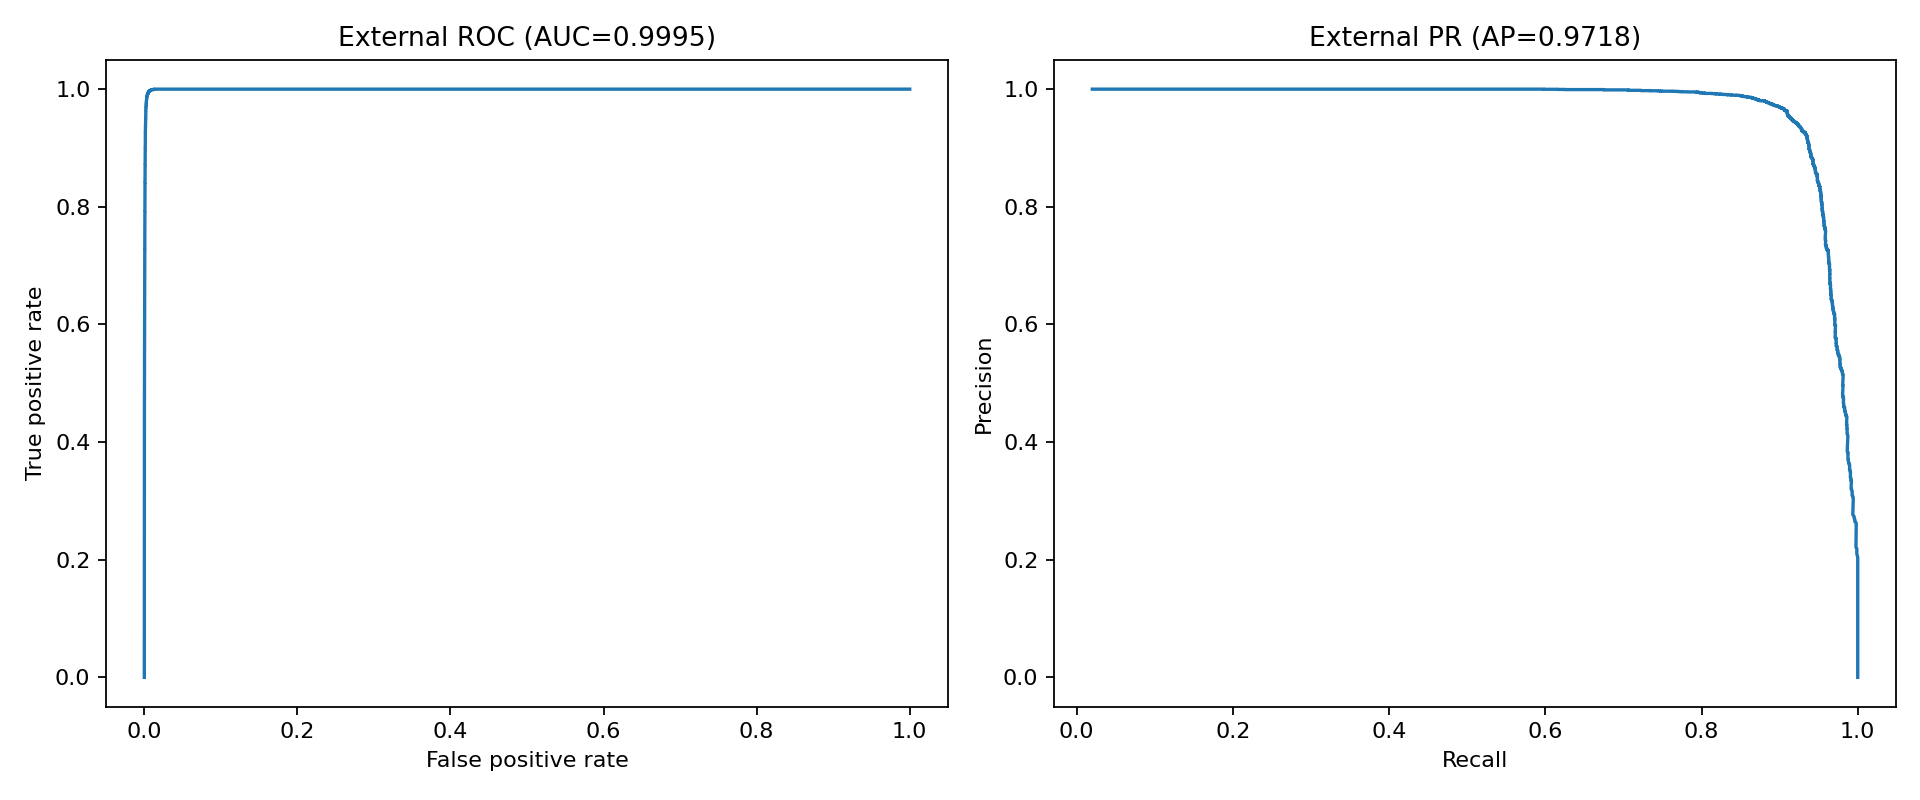

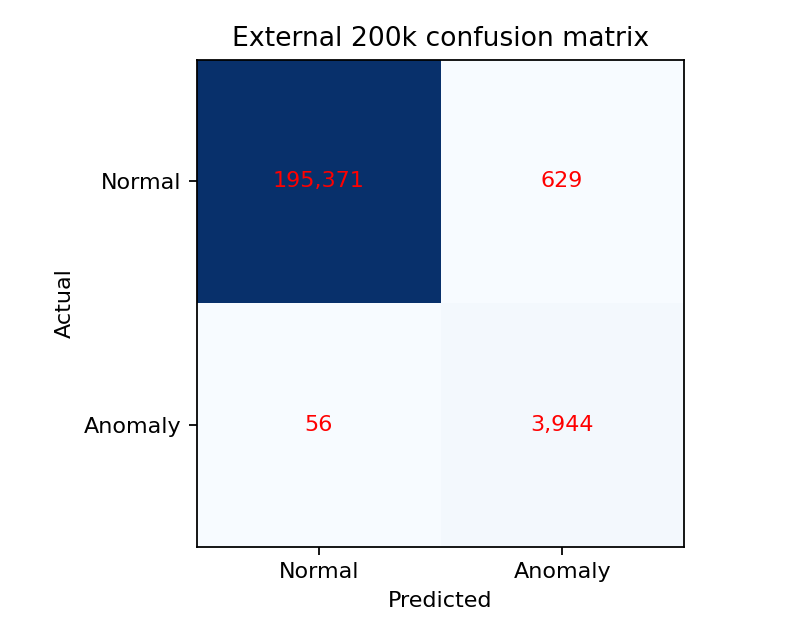

In [ ]:
from google.colab import files
import subprocess
import sys
from pathlib import Path
from IPython.display import display, Image

# Chọn file external_holdout_200k.py vừa tải
uploaded = files.upload()
assert "external_holdout_200k.py" in uploaded

# Dự đoán toàn bộ 200k và tính metrics
subprocess.run(
    [sys.executable, "-u", "external_holdout_200k.py"],
    check=True
)

# Hiển thị hai biểu đồ kết quả
result_dir = Path(
    "/content/drive/MyDrive/AnomalyBank/GATv2/"
    "skip-v2-runs/skip-v2-run-01/"
    "external-test-200k-seed-20261120"
)

for name in ["roc_pr.png", "confusion_matrix.png"]:
    display(Image(filename=str(result_dir / name), width=850))

In [ ]:

from pathlib import Path
import json
import numpy as np
from sklearn.metrics import (
    precision_recall_curve, precision_score,
    recall_score, f1_score, confusion_matrix,
    average_precision_score, roc_auc_score
)

repo = Path("/content/GATv2")
root = Path(
    "/content/drive/MyDrive/AnomalyBank/GATv2/"
    "skip-v2-runs/skip-v2-run-01/"
    "external-test-200k-seed-20261120"
)

# Đọc kết quả dự đoán đã chạy
with np.load(root / "predictions.npz", allow_pickle=False) as data:
    y = data["labels"].astype(int)
    scores = data["scores"].astype(float)
    ids = data["indices"]

assert len(y) == 200000
assert np.array_equal(ids, np.arange(200000))

original = json.loads(
    (root / "report.json").read_text(encoding="utf-8")
)
old_threshold = float(original["threshold"])

# Chia theo thời gian, không chia ngẫu nhiên
times = np.load(
    repo / "outputs/external-test-200k/"
    "seed-20261120/features-frozen-500k/"
    "request_timestamps_us.npy",
    mmap_mode="r"
)

order = np.argsort(times, kind="stable")
cal_idx = order[:40000]
test_idx = order[40000:]

assert len(test_idx) == 160000
assert len(np.unique(y[cal_idx])) == 2
assert len(np.unique(y[test_idx])) == 2

# Chọn threshold tối đa hóa F1 trên CALIBRATION
p, r, thresholds = precision_recall_curve(
    y[cal_idx], scores[cal_idx]
)

f1_values = 2 * p[:-1] * r[:-1] / np.maximum(
    p[:-1] + r[:-1], 1e-12
)

# Nếu hòa F1, chọn threshold cao hơn
best = np.flatnonzero(
    np.isclose(f1_values, f1_values.max(), rtol=0, atol=1e-12)
)[-1]

new_threshold = float(thresholds[best])

def evaluate(indices, threshold):
    actual = y[indices]
    pred = (scores[indices] >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        actual, pred, labels=[0, 1]
    ).ravel()

    return {
        "precision": float(precision_score(actual, pred, zero_division=0)),
        "recall": float(recall_score(actual, pred, zero_division=0)),
        "f1": float(f1_score(actual, pred, zero_division=0)),
        "tn": int(tn), "fp": int(fp),
        "fn": int(fn), "tp": int(tp)
    }

old_result = evaluate(test_idx, old_threshold)
new_result = evaluate(test_idx, new_threshold)

print("===== THRESHOLD OPTIMIZATION =====")
print("Method: F1-based post-hoc threshold tuning")
print("Calibration samples:", len(cal_idx))
print("Independent evaluation samples:", len(test_idx))
print("Old threshold:", old_threshold)
print("New threshold:", new_threshold)

print("\n===== EVALUATION ON SAME 160K =====")
for metric in ["precision", "recall", "f1"]:
    before = old_result[metric]
    after = new_result[metric]
    print(
        f"{metric:12s} OLD={before:.6f} "
        f"NEW={after:.6f} "
        f"DELTA={(after-before)*100:+.3f} pp"
    )

print("\nCONFUSION MATRIX")
print("Original:", {k: old_result[k] for k in ("tn", "fp", "fn", "tp")})
print("Adapted: ", {k: new_result[k] for k in ("tn", "fp", "fn", "tp")})

print("\nThreshold-independent metrics on 160k:")
print("AP:", average_precision_score(y[test_idx], scores[test_idx]))
print("ROC-AUC:", roc_auc_score(y[test_idx], scores[test_idx]))

# Lưu riêng, không ghi đè kết quả gốc
result = {
    "method": "Post-hoc F1-based threshold optimization",
    "split": "chronological 40k calibration / 160k evaluation",
    "old_threshold": old_threshold,
    "new_threshold": new_threshold,
    "original_on_160k": old_result,
    "adapted_on_160k": new_result,
    "note": "Post-hoc analysis; model weights are unchanged."
}

out = root / "threshold_calibration"
out.mkdir(exist_ok=True)
(out / "comparison.json").write_text(
    json.dumps(result, indent=2), encoding="utf-8"
)

print("\nTHRESHOLD CALIBRATION COMPLETE")


===== THRESHOLD OPTIMIZATION =====
Method: F1-based post-hoc threshold tuning
Calibration samples: 40000
Independent evaluation samples: 160000
Old threshold: 0.96233731508255
New threshold: 0.9964441657066345

===== EVALUATION ON SAME 160K =====
precision    OLD=0.913636 NEW=0.959262 DELTA=+4.563 pp
recall       OLD=0.992286 NEW=0.929960 DELTA=-6.233 pp
f1           OLD=0.951339 NEW=0.944384 DELTA=-0.696 pp

CONFUSION MATRIX
Original: {'tn': 156455, 'fp': 304, 'fn': 25, 'tp': 3216}
Adapted:  {'tn': 156631, 'fp': 128, 'fn': 227, 'tp': 3014}

Threshold-independent metrics on 160k:
AP: 0.9824288863918184
ROC-AUC: 0.999711052475702

THRESHOLD CALIBRATION COMPLETE


In [5]:

from google.colab import drive, files
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED

# 1. Kết nối lại Google Drive
drive.mount("/content/drive")

root = Path(
    "/content/drive/MyDrive/AnomalyBank/GATv2/"
    "skip-v2-runs/skip-v2-run-01"
)

result = root / "external-test-200k-seed-20261120"

# 2. Kiểm tra kết quả đã lưu
assert (root / "training/best.pt").is_file(), "Không thấy checkpoint!"
assert (result / "report.json").is_file(), "Không thấy báo cáo 200k!"

print("CHECKPOINT 5 EPOCHS: OK")
print("EXTERNAL TEST 200K: OK")

# 3. Chỉ đóng gói source config và báo cáo
items = {
    "reports/external-200k/report.json":
        result / "report.json",

    "reports/external-200k/threshold_comparison.json":
        result / "threshold_calibration/comparison.json",

    "reports/external-200k/roc_pr.png":
        result / "roc_pr.png",

    "reports/external-200k/confusion_matrix.png":
        result / "confusion_matrix.png",

    "configs/skip-v2-colab.json":
        root / "skip-v2-colab.json",
}

zip_path = Path("/content/GATv2_external200k_push.zip")

# 4. Tạo ZIP mới, không sử dụng ZIP lỗi trước đó
with ZipFile(zip_path, "w", ZIP_DEFLATED) as z:
    for name, path in items.items():
        if path.is_file():
            z.write(path, arcname=name)
            print("OK:", name)
        else:
            print("CHƯA CÓ:", name)

print("\nZIP HOÀN THÀNH:", zip_path)

# 5. Tải về máy
files.download(str(zip_path))


Mounted at /content/drive
CHECKPOINT 5 EPOCHS: OK
EXTERNAL TEST 200K: OK
OK: reports/external-200k/report.json
OK: reports/external-200k/threshold_comparison.json
OK: reports/external-200k/roc_pr.png
OK: reports/external-200k/confusion_matrix.png
OK: configs/skip-v2-colab.json

ZIP HOÀN THÀNH: /content/GATv2_external200k_push.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>